# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from pathlib import Path
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [2]:
SOURCE_URL = ("PFR attendance 2010-2019, e.g. https://www.pro-football-reference.com/years/2019/attendance.htm; "
              "nflverse games file, https://github.com/nflverse/nfldata; "
              "Census metro population, https://www2.census.gov/programs-surveys/popest/datasets/2010-2019/metro/totals/cbsa-est2019-alldata.csv")      # the page or file you downloaded from
DOWNLOAD_DATE = "2026-11-08"    # YYYY-MM-DD
FILE_NAME = "data/attendance.xlsx"        # the file as saved in your repository's data/ folder

**Who collected it, for what purpose, what is missing and why?**


The data was collected by Pro football reference. They track NFL data, and post the attendance report for teams each week. Teams count tickets sold for attendance, instead of people in stands. Also, games played internationally still count from a home game. The win % figure comes from nfl verse, which just sorted data from Pro Football Reference, which I verified myself. Metro population comes from the Census Bureau, and their yearly estimate for metro areas. There are no missing values, but demand past stadium capacity cannot be tracked. If fans wanted tickets after a game is sold out, that is demand we cannot track, and is MNAR.

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

In [3]:
ATT_URL = "https://raw.githubusercontent.com/Vir-Juneja/ECON3916-MIDTERM/main/data/attendance.xlsx"
GAMES_URL = "https://raw.githubusercontent.com/nflverse/nfldata/master/data/games.csv"
CENSUS_URL = "https://www2.census.gov/programs-surveys/popest/datasets/2010-2019/metro/totals/cbsa-est2019-alldata.csv"

# attendance from 2010-2019 using PFR data, split into sheets per season
pieces = []
for year in range(2010, 2020):
    sheet = pd.read_excel(ATT_URL, sheet_name=str(year))
    print(f"{year} raw attendance table: {sheet.shape}")
    sheet["season"] = year
    pieces.append(sheet)
raw_att = pd.concat(pieces, ignore_index=True)

att = raw_att[raw_att["Tm"].notna()].copy()          # removes league total frm each season
att = att[["season", "Tm", "Stadium", "Home"]]
att["home_att_per_game"] = att["Home"] / 8            # divided by 8 as each team played 8 home games per year
print(f"Attendance rows: {att.shape}")

# Win %, using nflverse data on github which is sourced from PFR (double checked)
games = pd.read_csv(GAMES_URL)
print(f"Games file: {games.shape}")
reg = games[(games["game_type"] == "REG") & (games["season"].between(2009, 2019))]

home = reg[["season", "home_team", "home_score", "away_score"]].copy()
home.columns = ["season", "team", "pf", "pa"]
away = reg[["season", "away_team", "away_score", "home_score"]].copy()
away.columns = ["season", "team", "pf", "pa"]
long = pd.concat([home, away], ignore_index=True)     # one row per team per game

# win = 1, loss = 0, tie = 0.5
long["win"] = (long["pf"] > long["pa"]).astype(float) + 0.5 * (long["pf"] == long["pa"]).astype(float)

codes = pd.DataFrame([
    ["ARI", "Cardinals"], ["ATL", "Falcons"], ["BAL", "Ravens"], ["BUF", "Bills"],
    ["CAR", "Panthers"], ["CHI", "Bears"], ["CIN", "Bengals"], ["CLE", "Browns"],
    ["DAL", "Cowboys"], ["DEN", "Broncos"], ["DET", "Lions"], ["GB", "Packers"],
    ["HOU", "Texans"], ["IND", "Colts"], ["JAX", "Jaguars"], ["KC", "Chiefs"],
    ["MIA", "Dolphins"], ["MIN", "Vikings"], ["NE", "Patriots"], ["NO", "Saints"],
    ["NYG", "Giants"], ["NYJ", "Jets"], ["OAK", "Raiders"], ["PHI", "Eagles"],
    ["PIT", "Steelers"], ["SD", "Chargers"], ["LAC", "Chargers"], ["SF", "49ers"],
    ["SEA", "Seahawks"], ["STL", "Rams"], ["LA", "Rams"], ["TB", "Buccaneers"],
    ["TEN", "Titans"], ["WAS", "Redskins"],
], columns=["team", "franchise"])
long = long.merge(codes, on="team", how="left")
print(f"Game rows with no team match: {long['franchise'].isna().sum()}")

wins = long.groupby(["franchise", "season"])["win"].mean().reset_index()
wins = wins.rename(columns={"win": "win_pct"})

# last season win %, moved forward, then merged back
prev = wins.copy()
prev["season"] = prev["season"] + 1
prev = prev.rename(columns={"win_pct": "prev_win_pct"})
wins = wins.merge(prev, on=["franchise", "season"], how="left")

# Census population,
cen = pd.read_csv(CENSUS_URL, encoding="latin-1")     # file had latin 1 encoding
print(f"Census file: {cen.shape}")
cen = cen[cen["LSAD"] == "Metropolitan Statistical Area"]
pieces = []
for year in range(2010, 2020):
    piece = cen[["CBSA"]].copy()
    piece["season"] = year
    piece["metro_pop"] = cen[f"POPESTIMATE{year}"]
    pieces.append(piece)
pop = pd.concat(pieces, ignore_index=True)

# Joins
teams = pd.DataFrame([
    ["Arizona Cardinals", "Cardinals", 38060], ["Atlanta Falcons", "Falcons", 12060],
    ["Baltimore Ravens", "Ravens", 12580], ["Buffalo Bills", "Bills", 15380],
    ["Carolina Panthers", "Panthers", 16740], ["Chicago Bears", "Bears", 16980],
    ["Cincinnati Bengals", "Bengals", 17140], ["Cleveland Browns", "Browns", 17460],
    ["Dallas Cowboys", "Cowboys", 19100], ["Denver Broncos", "Broncos", 19740],
    ["Detroit Lions", "Lions", 19820], ["Green Bay Packers", "Packers", 24580],
    ["Houston Texans", "Texans", 26420], ["Indianapolis Colts", "Colts", 26900],
    ["Jacksonville Jaguars", "Jaguars", 27260], ["Kansas City Chiefs", "Chiefs", 28140],
    ["Miami Dolphins", "Dolphins", 33100], ["Minnesota Vikings", "Vikings", 33460],
    ["New England Patriots", "Patriots", 14460], ["New Orleans Saints", "Saints", 35380],
    ["New York Giants", "Giants", 35620], ["New York Jets", "Jets", 35620],
    ["Oakland Raiders", "Raiders", 41860], ["Philadelphia Eagles", "Eagles", 37980],
    ["Pittsburgh Steelers", "Steelers", 38300], ["San Diego Chargers", "Chargers", 41740],
    ["Los Angeles Chargers", "Chargers", 31080], ["San Francisco 49ers", "49ers", 41860],
    ["Seattle Seahawks", "Seahawks", 42660], ["St. Louis Rams", "Rams", 41180],
    ["Los Angeles Rams", "Rams", 31080], ["Tampa Bay Buccaneers", "Buccaneers", 45300],
    ["Tennessee Titans", "Titans", 34980], ["Washington Redskins", "Redskins", 47900],
], columns=["Tm", "franchise", "CBSA"])

df = att.merge(teams, on="Tm", how="left")
print(f"\nAttendance rows with no team match: {df['CBSA'].isna().sum()}")
df = df.merge(wins, on=["franchise", "season"], how="left")
df = df.merge(pop, on=["CBSA", "season"], how="left")
df["log_metro_pop"] = np.log(df["metro_pop"])

print(f"Final dataset (rows, columns): {df.shape}")
print(f"\nMissing values per column:\n{df.isna().sum()}")

2010 raw attendance table: (33, 22)
2011 raw attendance table: (33, 22)
2012 raw attendance table: (33, 22)
2013 raw attendance table: (33, 22)
2014 raw attendance table: (33, 22)
2015 raw attendance table: (33, 22)
2016 raw attendance table: (33, 22)
2017 raw attendance table: (33, 22)
2018 raw attendance table: (33, 22)
2019 raw attendance table: (33, 22)
Attendance rows: (320, 5)
Games file: (7548, 46)
Game rows with no team match: 0
Census file: (2797, 97)

Attendance rows with no team match: 0
Final dataset (rows, columns): (320, 11)

Missing values per column:
season               0
Tm                   0
Stadium              0
Home                 0
home_att_per_game    0
franchise            0
CBSA                 0
win_pct              0
prev_win_pct         0
metro_pop            0
log_metro_pop        0
dtype: int64


In [4]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "team-season"        # one row is one what? e.g. "county" or "country-year"
OUTCOME = "home_att_per_game"     # your dependent variable's column name
MAIN_X = "win_pct"      # your main explanatory variable's column name
CONTROLS = ["prev_win_pct", "log_metro_pop", "Tm", "season"]    # every other column in your model

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 320   Columns: 11   One row is: team-season

Missing values per column:
home_att_per_game    0
win_pct              0
prev_win_pct         0
log_metro_pop        0
Tm                   0
season               0

Skew of home_att_per_game: -0.49 (above about 1, consider a log)


**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.
2. Are all your variables in the same units and for the same years?
3. If your question is about a policy, where is the period before it?

*Your answers here.*
1. No, the seasons win % does not change any of my controls. The last season win %, metro population, the team, and the year are all fixed and will not change with this.
2. Yes, every row is a team-season from 2010 to 2019. Attendance and population are always tracked in the same unit, people. The data starts from 2009 so we have the win % from the last season for 2010.
3. N/A, not a policy question.

In [5]:
rows = []
for col, label, scale in [
    ("home_att_per_game", "Home attendance per game (thousands)", 1000),
    ("win_pct", "Win % this season (0 to 1)", 1),
    ("prev_win_pct", "Win % last season (0 to 1)", 1),
    ("metro_pop", "Metro population (millions)", 1000000),
]:
    values = df[col] / scale
    rows.append([label, values.count(), values.mean(), values.median(), values.std(), values.min(), values.max()])

summary = pd.DataFrame(rows, columns=["Variable", "N", "Mean", "Median", "Std. dev.", "Min", "Max"]).round(2)
summary

,Variable,N,Mean,Median,Std. dev.,Min,Max
0,Home attendance per game (thousands),320,67.81,68.46,8.70,25.34,92.72
1,Win % this season (0 to 1),320,0.50,0.50,0.19,0.00,0.94
2,Win % last season (0 to 1),320,0.50,0.50,0.19,0.00,0.94
3,Metro population (millions),320,4.87,3.50,4.44,0.31,19.33


Question:
For NFL teams from 2010 to 2019, how does a teams winning percentage relate to how many fans attend home games, controlled for last seasons win percentage and the size of its metro area.

Why Does it matter. Teams use this when they set ticket prices, and when spending money in free agency. The cities care too, as stadiums are often tax-payer funded.

The summary table: The data has 320 team-season (32 teams * 10 years). The average home game drew 67,800 fans, roughly. The range runs from 25,300 to 92,700, the lower end being due to a chargers season with reduced stadium capacity. The win % ranges from 0, to .94 (15-1 packers, and 0-16 browns). It averages out to .500, as the amount of games played is even (if one team loses, another has to win, and ties are .500 for both). Metro population ranges from .3 million in Wisconsin to nearly 20 million in New York City and New Jersey areas. Since attendance has a slight left skew, I decided not to take its log.

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

Share of team-seasons with 60,000-75,000 fans per game: 70%
Skew of attendance per game: -0.49


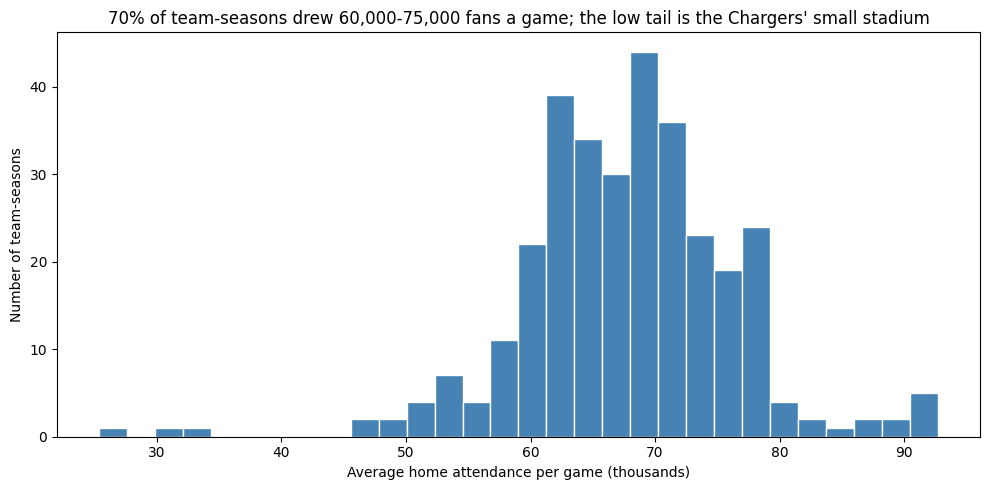

Correlation between win % and attendance per game: 0.15
Fitted line: 6.7 thousand more fans per game for a 0-to-1 change in win %


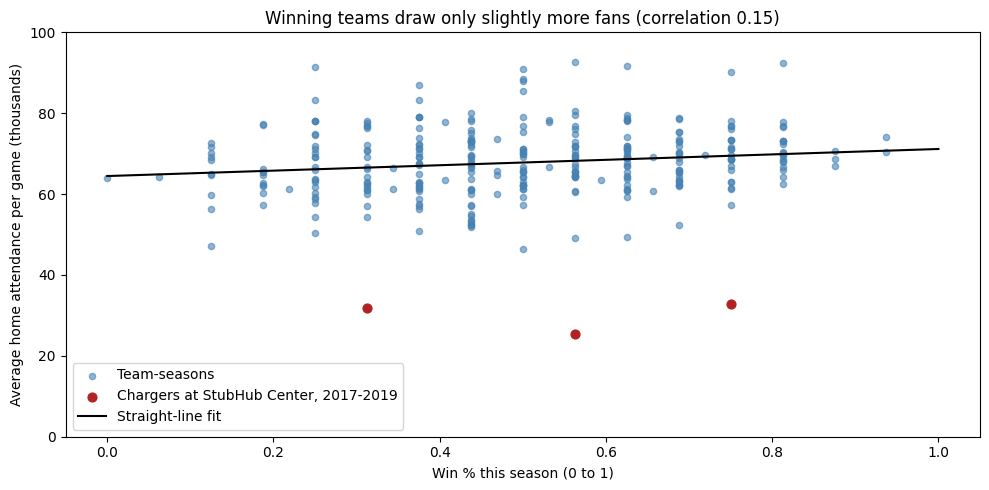

In [6]:
Path("figures").mkdir(exist_ok=True)

# Figure 1, outcome shape
att_k = df["home_att_per_game"] / 1000
share_60_75 = ((att_k >= 60) & (att_k <= 75)).mean()
print(f"Share of team-seasons with 60,000-75,000 fans per game: {share_60_75:.0%}")
print(f"Skew of attendance per game: {df['home_att_per_game'].skew():.2f}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(att_k, bins=30, color="steelblue", edgecolor="white")
ax.set_xlabel("Average home attendance per game (thousands)")
ax.set_ylabel("Number of team-seasons")
ax.set_title(f"{share_60_75:.0%} of team-seasons drew 60,000-75,000 fans a game; the low tail is the Chargers' small stadium")
plt.tight_layout()
plt.savefig("figures/fig1_attendance_hist.png", dpi=150, bbox_inches="tight")
plt.show()

# Figure 2, winning and attendance
corr = np.corrcoef(df["win_pct"], df["home_att_per_game"])[0, 1]
line = sm.OLS(att_k, sm.add_constant(df["win_pct"])).fit()
print(f"Correlation between win % and attendance per game: {corr:.2f}")
print(f"Fitted line: {line.params['win_pct']:.1f} thousand more fans per game for a 0-to-1 change in win %")

chargers = df["Stadium"] == "StubHub Center"
xs = np.linspace(0, 1, 50)
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(df["win_pct"], att_k, s=20, alpha=0.6, color="steelblue", label="Team-seasons")
ax.scatter(df.loc[chargers, "win_pct"], att_k[chargers], s=40, color="firebrick",
           label="Chargers at StubHub Center, 2017-2019")
ax.plot(xs, line.params["const"] + line.params["win_pct"] * xs, color="black", lw=1.5, label="Straight-line fit")
ax.set_ylim(0, 100)                     # starts at zero so the slope isn't exaggerated
ax.set_xlabel("Win % this season (0 to 1)")
ax.set_ylabel("Average home attendance per game (thousands)")
ax.set_title(f"Winning teams draw only slightly more fans (correlation {corr:.2f})")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig2_win_vs_attendance.png", dpi=150, bbox_inches="tight")
plt.show()

Figure 1. About 70% of team-seasons drew between 60,000 and 75,000 fans per home game. The low values are the chargers three seasons at StubHub Center, which had a maximum capacity of circa 27,000 seats. Attendance does still have a slight left skew, so I chose not to call for a log.

Figure 2.  Teams that win more draw a few more fans, but not a lot more. The correlation is about 0.15, and the difference between winning no games and winning every game only lines up with about 7000 more fans per game. This is about 10% of an average crowd, and the spread between teams at the same win % can be larger than that. This makes sense if almost all stadiums are close to full, as demand cannot be tracked beyond capacity. The data is not misrepresented by the graph, as the y axis starts at zero, so it is an accurate reflection of the slope.

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [7]:
#Regressors, the 3 variables, and team and year dummies
teams = sorted(df["Tm"].unique())      # 34 team-city units, Rams and chargers moved
years = sorted(df["season"].unique())
def build_X(variables, dummies=True):
    """The listed columns, plus team and year dummies if dummies=True, plus a constant."""
    X = df[variables].astype(float).copy()
    if dummies:
        for team in teams[1:]:          # first team left out to be comparison group
            X[f"team {team}"] = (df["Tm"] == team).astype(float)
        for year in years[1:]:          # 2010 left out to be compairson year
            X[f"year {year}"] = (df["season"] == year).astype(float)
    return sm.add_constant(X)

y = df["home_att_per_game"]
main = sm.OLS(y, build_X(["win_pct", "prev_win_pct", "log_metro_pop"])).fit()
no_pop = sm.OLS(y, build_X(["win_pct", "prev_win_pct"])).fit()
no_dummies = sm.OLS(y, build_X(["win_pct", "prev_win_pct", "log_metro_pop"], dummies=False)).fit()

# Regression table, the coefficient with its standard error in parentheses
models = [("(1) Main", main), ("(2) No population", no_pop), ("(3) No dummies", no_dummies)]
terms = [("win_pct", "Win % this season"),
         ("prev_win_pct", "Win % last season"),
         ("log_metro_pop", "Log metro population")]

header = f"{'Outcome: home attendance per game':<34}"
for name, m in models:
    header += f"{name:>20}"
print(header)
print("-" * 94)
for var, label in terms:
    coef_line = f"{label:<34}"
    se_line = f"{'':<34}"
    for name, m in models:
        if var in m.params.index:
            se_text = f"({m.bse[var]:,.0f})"
            coef_line += f"{m.params[var]:>20,.0f}"
            se_line += f"{se_text:>20}"
        else:
            coef_line += f"{'':>20}"
            se_line += f"{'':>20}"
    print(coef_line)
    print(se_line)
print("-" * 94)
for label, flags in [("Team dummies", ["Yes", "Yes", "No"]), ("Year dummies", ["Yes", "Yes", "No"])]:
    line = f"{label:<34}"
    for flag in flags:
        line += f"{flag:>20}"
    print(line)
n_line = f"{'N (team-seasons)':<34}"
r2_line = f"{'R-squared':<34}"
for name, m in models:
    n_line += f"{int(m.nobs):>20}"
    r2_line += f"{m.rsquared:>20.3f}"
print(n_line)
print(r2_line)
print("Standard errors in parentheses (classical). Section 4 checks whether robust errors are needed.")

# Interpretation numbers
avg_att = y.mean()
for var, label in terms[:2]:
    lo, hi = main.conf_int().loc[var]
    per_tenth = main.params[var] * 0.1
    print(f"\n{label}: {per_tenth:,.0f} more fans per game for a 0.1 rise "
          f"({per_tenth / avg_att:.1%} of an average crowd of {avg_att:,.0f})")
    print(f"   95% CI for the full coefficient: [{lo:,.0f}, {hi:,.0f}]   p = {main.pvalues[var]:.3f}")

Outcome: home attendance per game             (1) Main   (2) No population      (3) No dummies
----------------------------------------------------------------------------------------------
Win % this season                                1,369               1,365               4,468
                                                 (998)               (995)             (2,622)
Win % last season                                4,575               4,572               7,770
                                                 (995)               (992)             (2,615)
Log metro population                              -559                                   1,212
                                               (8,071)                                   (582)
----------------------------------------------------------------------------------------------
Team dummies                                       Yes                 Yes                  No
Year dummies                                      

The main result.
Column 1 is my main model. Win percentage runs from 0 to 1, So I am looking at a 0.1 change, which equates to 1.6 more wins in a 16 game season.

Win Percentage this season. A 0.1 rise in this seasons win % is associated with about 137 more fans per home game, holding last seasons record, metro size, the team, and the year fixed. That is a very small figure, roughly 0.2% of the average crowd size of 67,806. The estimate is also not precise, the standard error of (998) is close to the coefficient size of 1369. The 95% confidence interval runs from about -600 to +3300, so I cannot rule out that winning this season makes no difference.

Win % from last season: A 0.1 rise in last seasons win % goes with about 458 more fans per home game, with all else fixed. This is also a small figure, roughly 0.7% of an average crowd. This measure is very precise, the 95% interval runs from about 2600 to 6500, which is well above zero (P < .001). Fans seem to buy off last years team, which makes sense, as tickets are sold before the season starts.

Why I used each control.

Last seasons win % blocks a confounding path. It drives the ticket sales for this year, and is also a strong predictor of record this year. It works well as it is fixed, and this season's results cannot change it, as last year's results happened first.

Team dummies block confounding from aspects of each team that stay the same, like stadium size, fan loyalty, and market. Without them, the win% effect would triple, and R squared would fall from .91 to 0.06. This shows how much of the pattern are winning teams in big markets. They would only be a bad control if winning could change what team you are, but it can not.

Year dummies help to add precision to the measure, by picking up major changes in the league (like a new TV deal) or the economy, or major events. They would only be bad control if winning could change what year it is, but it cannot.

Metro population is for additional precision. It does not change much within a city over ten years, so most of it is covered by team dummies. The estimate for it is close to zero, and has a huge standard error. (-559 estimate, and standard error of 8071). Dropping it leaves everything else almost the same. It is a good control as winning does not cause a growth in population, or at least is very unlikely to.

I did not include making the playoffs as it is directly caused by winning, and would be on the path from win% to attendance. Controlling for it would take away part of the effect I am trying to measure.



## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

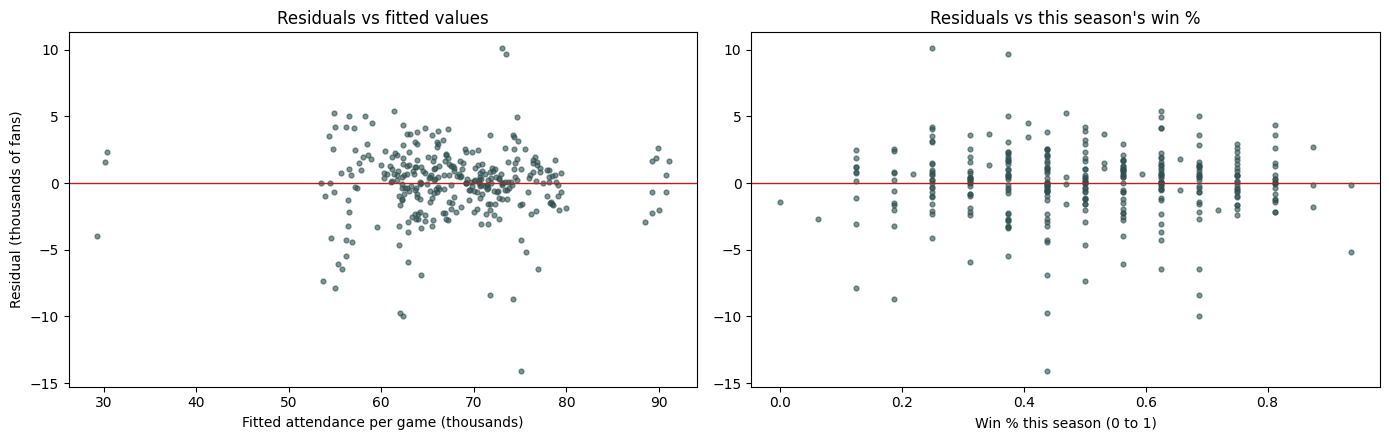

Breusch-Pagan: LM = 106.0, p = 7.9e-07

term                       coef  classical SE   HC3 SE  cluster SE   HC3 p  cluster p
-------------------------------------------------------------------------------------
Win % this season         1,369           998    1,145       1,146   0.233      0.241
Win % last season         4,575           995    1,122       1,426   0.000      0.003
Log metro population       -559         8,071    6,574      10,080   0.932      0.956
Clusters: 32 franchises
Win % this season: 95% CI with clustered errors [-968, 3,706]
Win % last season: 95% CI with clustered errors [1,666, 7,484]

term                         VIF
--------------------------------
Win % this season            1.4
Win % last season            1.4
Log metro population      1698.6

team-season                     attendance  leverage  std resid   Cook D
------------------------------------------------------------------------
Los Angeles Rams 2016               83,165     0.290       4.19    0

In [8]:
X_main = build_X(["win_pct", "prev_win_pct", "log_metro_pop"])

#Residual plots, against fitted values and against this seasons win %
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(main.fittedvalues / 1000, main.resid / 1000, s=12, alpha=0.6, color="darkslategray")
axes[0].axhline(0, color="firebrick", lw=1)
axes[0].set_xlabel("Fitted attendance per game (thousands)")
axes[0].set_ylabel("Residual (thousands of fans)")
axes[0].set_title("Residuals vs fitted values")
axes[1].scatter(df["win_pct"], main.resid / 1000, s=12, alpha=0.6, color="darkslategray")
axes[1].axhline(0, color="firebrick", lw=1)
axes[1].set_xlabel("Win % this season (0 to 1)")
axes[1].set_title("Residuals vs this season's win %")
plt.tight_layout()
plt.savefig("figures/fig3_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

# Constant variance: Breusch Pagan, and then robust and clustered errors
bp = het_breuschpagan(main.resid, main.model.exog)
print(f"Breusch-Pagan: LM = {bp[0]:.1f}, p = {bp[1]:.2g}")

main_hc3 = sm.OLS(y, X_main).fit(cov_type="HC3", use_t=True)
# every franchise appears 10 times, its errors might move together
main_cl = sm.OLS(y, X_main).fit(cov_type="cluster", cov_kwds={"groups": df["franchise"]}, use_t=True)

print(f"\n{'term':<22}{'coef':>9}{'classical SE':>14}{'HC3 SE':>9}{'cluster SE':>12}{'HC3 p':>8}{'cluster p':>11}")
print("-" * 85)
for var, label in terms:
    print(f"{label:<22}{main.params[var]:>9,.0f}{main.bse[var]:>14,.0f}{main_hc3.bse[var]:>9,.0f}"
          f"{main_cl.bse[var]:>12,.0f}{main_hc3.pvalues[var]:>8.3f}{main_cl.pvalues[var]:>11.3f}")
print(f"Clusters: {len(df['franchise'].unique())} franchises")
for var, label in terms[:2]:
    lo, hi = main_cl.conf_int().loc[var]
    print(f"{label}: 95% CI with clustered errors [{lo:,.0f}, {hi:,.0f}]")

# Variance inflation factors
Xv = X_main.values
vif = {}
print(f"\n{'term':<22}{'VIF':>10}")
print("-" * 32)
for i, name in enumerate(X_main.columns):
    for var, label in terms:
        if name == var:
            vif[var] = variance_inflation_factor(Xv, i)
            print(f"{label:<22}{vif[var]:>10.1f}")

# Influence, leverage, standardised residual, and Cooks distance
infl = main.get_influence()
lev = infl.hat_matrix_diag
std_resid = infl.resid_studentized_internal
cooks = infl.cooks_distance[0]
order = np.argsort(cooks)[::-1][:5]      #largest 5 cooks distances, largest first

print(f"\n{'team-season':<30}{'attendance':>12}{'leverage':>10}{'std resid':>11}{'Cook D':>9}")
print("-" * 72)
for i in order:
    name = f"{df['Tm'].iloc[i]} {df['season'].iloc[i]}"
    print(f"{name:<30}{df['home_att_per_game'].iloc[i]:>12,.0f}{lev[i]:>10.3f}{std_resid[i]:>11.2f}{cooks[i]:>9.3f}")
print(f"\nCook's D above 4/n ({4 / len(df):.4f}): {(cooks > 4 / len(df)).sum()} of {len(df)} team-seasons")

# fit without most influential team-season
top = order[0]
without = sm.OLS(y.drop(y.index[top]), X_main.drop(X_main.index[top])).fit()
print(f"\nWithout {df['Tm'].iloc[top]} {df['season'].iloc[top]}:")
for var, label in terms[:2]:
    shift = without.params[var] - main.params[var]
    print(f"  {label}: {main.params[var]:,.0f} -> {without.params[var]:,.0f} "
          f"(moved {abs(shift) / main.bse[var]:.2f} of its standard error)")



Residual Plots: Neither plot shows a curve, so we can use a straight line as a fair fit. The spread against the fitted values is not even, it is widest for team-seasons with fitted attendance in the mid 50,000s to low 60,000s, and tighest for the highest drawing teams. This makes sense, as we talked about a potential capacity problem, teams that are near capacity of their stadium cannot go much higher, so the errors will build up there.

Constant Variance:
The Breusch Pagan test rejects constant variance,(LM = 106.0, p = 7.9 * 10 ^-7), so the classical standard errors I used in section 3 are too small. I used HC3 robust errors instead. Each team appears ten times, and their runs of poor and excellent attendance usually came in successive runs, so I decided to cluster the errors by Franchise. I treat the clustered errors as final.

Clustering errors does not change the main results. This seasons win % is still imprecise, with standard error being 1,146, p = 0.24, and the 95% interval is about -1000 to + 3700. Last seasons win % is still very clearly positive, standard error 1,426, p = 0.003, interval being about 1700 to 7500. The standard error went up by almost half, meaning that the clustering did matter.

Inflation Factors: Both of the win % variables have a VIF of about 1.4. That is pretty low, which means while this season and last seasons records are related, they are not close to being copies of one another. Log metro population has a VIF 1700. This means, with team dummies included, it is almost a copy, which makes sense as city populations do not have great fluctuations within 10 year. This is likely what caused the massive standard error. This still only damages the standard error of that one variable, and not the others, which is why dropping it in column 2 did not change the win %

Influential Observations
: The most influential team-seasons were almost all related to stadium changes or issues. The rams in 2016 and 2017 were their first two seasons back in LA. The crowds were huge in the first year, and then fell back down. They also have high leverage because the LA rams only have 4 seasons of data. The Redskins in 2018 experienced a sharp drop in attendance, due to controversies around their owner. This was a boycott to pressure him into selling the team. The Vikings in 2014 and 2015 played in a smaller temporary stadium, which had a capacity limit.

Dropping the most influential team season (Rams-2016) moves this seasons win % from 1369 to 1939, which is about half of its standard error. It barely moves last seasons (4575 to 4739), so it shows that neither conclusion changes and the results do not hinge on one odd season.

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.


There are multiple threats. For the win % coefficient to truly be causal, we would want nothing else that changes from year to year to affect both winning and crowds. There are a few threats in this case
Price: If teams raise ticket prices after winning, it would crowd out some fans, and make winning look like it matters less than it actually does.
Capacity: Sold out stadiums are capped in terms of attendance, which pushes the estimate towards zero.
Excitement: a new star player or acquisition could help drive "hype" and projected wins, driving up both wins and ticket sales, pushing the estimate up.
Reverse causation: it is possible that big crowds help teams win at home, so the arrow could run backwards a bit.

I would say my estimate is not causal, it is more likely a conditional association: within the same team, and compared with the same season across the league, how attendance moves with winning, holding last seasons record and metro size fixed.

Conclusion: Within a team, crowd sizes will move very little with this seasons winning. A 0.1 rise in win % is associated with about 137 more fans per game, and I cannot rule out zero. Last seasons record matters much more, as a 0.1 rise in win % is associated with about 458 more fans per game. This holds up with clustered and robust errors, even factoring for the drop of most influential season. A reader can be fairly confident that last seasons record is linked to attendance, but should not read that as the impact winning has on demand, due to the threats. With another month, I would add ticket prices to the model, and use game by game data to see within season changes, and factor for stadium capacity so I could model sold out games.

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

In [9]:
# Full main model with clustered errors, including every team and year dummy
print(f"{'term':<36}{'coef':>10}{'cluster SE':>12}")
print("-" * 58)
for name in main_cl.params.index:
    print(f"{name:<36}{main_cl.params[name]:>10,.0f}{main_cl.bse[name]:>12,.0f}")
print("\nFigures are saved in figures/: fig1_attendance_hist.png, fig2_win_vs_attendance.png, fig3_residuals.png")

term                                      coef  cluster SE
----------------------------------------------------------
const                                   67,078     154,186
win_pct                                  1,369       1,146
prev_win_pct                             4,575       1,426
log_metro_pop                             -559      10,080
team Atlanta Falcons                     7,878       2,201
team Baltimore Ravens                    7,701       4,984
team Buffalo Bills                       2,630      14,009
team Carolina Panthers                  10,429       6,305
team Chicago Bears                        -133       7,449
team Cincinnati Bengals                 -5,941       7,405
team Cleveland Browns                    5,002       7,980
team Dallas Cowboys                     27,315       4,316
team Denver Broncos                     13,209       4,993
team Detroit Lions                         -71         546
team Green Bay Packers                  11,077      26,9

## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [10]:
REPORT_NUMBERS = {
    "Section 1: team-seasons in the final sample": len(df),
    "Section 1: average home attendance per game": round(avg_att),
    "Section 2: median home attendance per game": round(df["home_att_per_game"].median()),
    "Section 2: share of team-seasons with 60,000-75,000 fans per game": f"{share_60_75:.0%}",
    "Section 2: skew of attendance per game": round(df["home_att_per_game"].skew(), 2),
    "Section 2: correlation of win % and attendance": round(corr, 2),
    "Section 2: fitted line, thousand fans per game from 0 to 1 win %": round(sm.OLS(df["home_att_per_game"] / 1000, sm.add_constant(df["win_pct"])).fit().params["win_pct"], 1),
    "Section 3: R-squared, main model": round(main.rsquared, 3),
    "Section 3: R-squared, no dummies": round(no_dummies.rsquared, 3),
    "Section 3: R-squared, no population": round(no_pop.rsquared, 3),
    "Section 4: Breusch-Pagan LM": round(bp[0], 1),
    "Section 4: Breusch-Pagan p-value": f"{bp[1]:.2g}",
    "Section 4: clusters (franchises)": len(df["franchise"].unique()),
    "Section 4: Cook's D cutoff 4/n": round(4 / len(df), 4),
    "Section 4: team-seasons above the cutoff": int((cooks > 4 / len(df)).sum()),
}
for name, m in [("(1) main", main), ("(2) no population", no_pop), ("(3) no dummies", no_dummies)]:
    for var, label in terms:
        if var in m.params.index:
            REPORT_NUMBERS[f"Table A1 {name}: {label}, coefficient (classical SE)"] = f"{m.params[var]:,.0f} ({m.bse[var]:,.0f})"
for var, label in terms:
    REPORT_NUMBERS[f"Table A2: {label}, HC3 SE / p"] = f"{main_hc3.bse[var]:,.0f} / {main_hc3.pvalues[var]:.3f}"
    REPORT_NUMBERS[f"Table A2: {label}, cluster SE / p"] = f"{main_cl.bse[var]:,.0f} / {main_cl.pvalues[var]:.3f}"
    REPORT_NUMBERS[f"Section 4: {label}, VIF"] = round(vif[var], 1)
for var, label in terms[:2]:
    lo, hi = main.conf_int().loc[var]
    clo, chi = main_cl.conf_int().loc[var]
    REPORT_NUMBERS[f"Section 3: {label}, fans per 0.1 rise"] = round(main.params[var] * 0.1)
    REPORT_NUMBERS[f"Section 3: {label}, share of an average crowd per 0.1"] = f"{main.params[var] * 0.1 / avg_att:.1%}"
    REPORT_NUMBERS[f"Section 3: {label}, classical 95% CI / p"] = f"[{lo:,.0f}, {hi:,.0f}] / {main.pvalues[var]:.3f}"
    REPORT_NUMBERS[f"Section 4: {label}, clustered 95% CI"] = f"[{clo:,.0f}, {chi:,.0f}]"
    REPORT_NUMBERS[f"Section 4: {label}, without the most influential season"] = round(without.params[var])
    REPORT_NUMBERS[f"Section 4: {label}, shift in standard errors"] = round(abs(without.params[var] - main.params[var]) / main.bse[var], 2)
for i in order:
    REPORT_NUMBERS[f"Table A3: {df['Tm'].iloc[i]} {df['season'].iloc[i]}"] = (
        f"attendance {df['home_att_per_game'].iloc[i]:,.0f}, leverage {lev[i]:.3f}, "
        f"std resid {std_resid[i]:.2f}, Cook's D {cooks[i]:.3f}")

print("Table 1 (summary statistics):")
print(summary.to_string())
print()
for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

Table 1 (summary statistics):
                               Variable    N   Mean  Median  Std. dev.    Min    Max
0  Home attendance per game (thousands)  320  67.81   68.46       8.70  25.34  92.72
1            Win % this season (0 to 1)  320   0.50    0.50       0.19   0.00   0.94
2            Win % last season (0 to 1)  320   0.50    0.50       0.19   0.00   0.94
3           Metro population (millions)  320   4.87    3.50       4.44   0.31  19.33

Section 1: team-seasons in the final sample: 320
Section 1: average home attendance per game: 67806
Section 2: median home attendance per game: 68460
Section 2: share of team-seasons with 60,000-75,000 fans per game: 70%
Section 2: skew of attendance per game: -0.49
Section 2: correlation of win % and attendance: 0.15
Section 2: fitted line, thousand fans per game from 0 to 1 win %: 6.7
Section 3: R-squared, main model: 0.907
Section 3: R-squared, no dummies: 0.06
Section 3: R-squared, no population: 0.907
Section 4: Breusch-Pagan LM: 106

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.